# Clustering packets of WPT using k-means method
Here we use energy, kurtosis and skewness for k-means clustering and thresholding.

In [1]:
import sys

if sys.version_info[0] + 0.1 * sys.version_info[1] < 3.6:
    raise Exception("Must be using Python 3.6+ version")

In [2]:

%matplotlib inline
sys.path.append("..")
from wavelet_transform.wpt import transform as wpt
from wavelet_transform.test import synthetic_data as sd
from wavelet_transform.wpt import inverse_transform as inv
from wavelet_transform.postprocess import plotting as plot
import wavelet_transform.utils.statistical_features as stats

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

### Parameters

Specify parameters for synthetic data and wavelet transform

In [3]:
# keep the same
sampling_rate = 100  # unit: Hz

# PARAMETERS TO CHANGE
amplitudes = [0.4, 1]  # amplitude of each sine wave
frequencies = [5, 13]  # frequency content of signal
phases = [0, np.deg2rad(45)]  # phase of each sine wave

duration = 300 / min(frequencies)  # duration of wave

trans_amp = [1 for _ in range(1)]  # amplitudes of transients
n_trans = len(trans_amp)  # number of transients
trans_dur = [0.05 for _ in range(n_trans)]  # duration of transients
trans_time = [
    duration * i / (n_trans + 1) for i in range(1, n_trans + 1)
]  # times of transients

std_noise = 0.1

wavelet = "db20"
levels = 5
mode = "symmetric"

fft_lim = 50  # increase value to view more of the fft plots

### Generating synthetic data

Generate synthetic data with transients, noise, and harmonics. Plot the data with its FFT. 

/tmp/ipykernel_1618846/1457866422.py:25: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


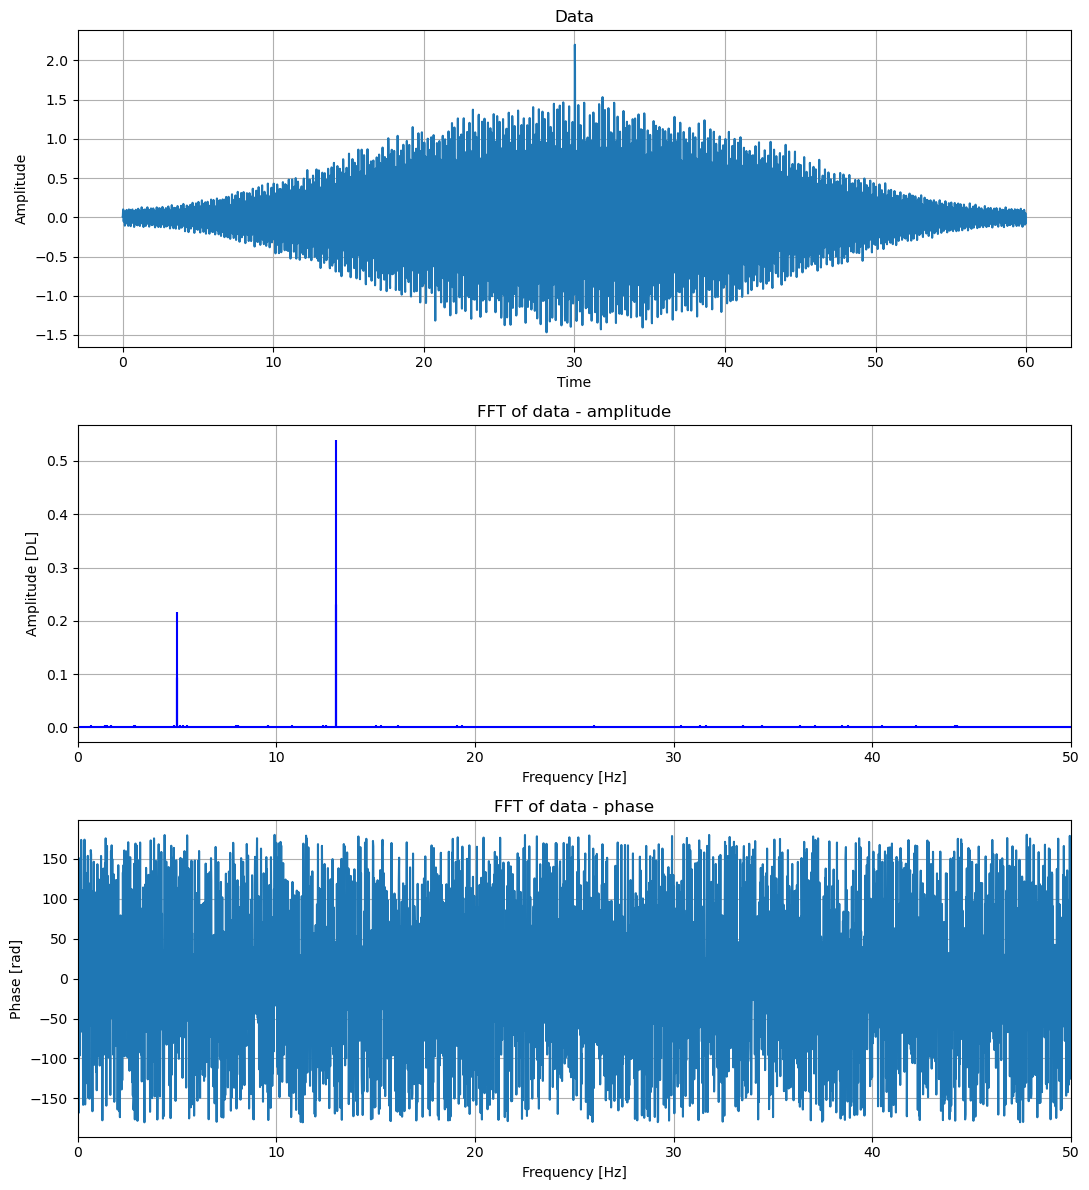

In [4]:
# generate sound wave

data, t_plot = sd.sound_wave(amplitudes, frequencies, phases, duration, sampling_rate)
signal_length = len(data)
transient_signal = sd.transients(
    trans_amp, trans_time, trans_dur, duration, sampling_rate
)
data += transient_signal
data += sd.noise(std_noise, duration, sampling_rate)
data *= np.hamming(signal_length)

fft_data = np.fft.fft(data)[0 : int(signal_length / 2)] / (
    signal_length / 2
)  # division by signal_length/2 is to correct the amplitude (energy) in the freq domain
freq = np.fft.fftfreq(signal_length, d=1 / sampling_rate)[0 : int(signal_length / 2)]

# plot sound wave and fft
fig, ax = plt.subplots(3, figsize=(11, 12))
ax[0].plot(t_plot, data)
ax[0].set_title("Data")
ax[0].set_xlabel("Time")
ax[0].set_ylabel("Amplitude")
ax[0].grid()

ax[1].stem(
    freq,
    np.abs(fft_data),
    linefmt="b",
    markerfmt=" ",
    basefmt="-b",
    use_line_collection=True,
)
ax[1].set_title("FFT of data - amplitude")
ax[1].set_xlabel("Frequency [Hz]")
ax[1].set_ylabel("Amplitude [DL]")
ax[1].set_xlim(0, sampling_rate / 2)
ax[1].grid()

ax[2].plot(freq, np.angle(fft_data, deg=True))
ax[2].set_title("FFT of data - phase")
ax[2].set_xlabel("Frequency [Hz]")
ax[2].set_ylabel("Phase [rad]")
ax[2].set_xlim(0, sampling_rate / 2)
ax[2].grid()
fig.tight_layout()
plt.show()

Calculating crest factor and energy

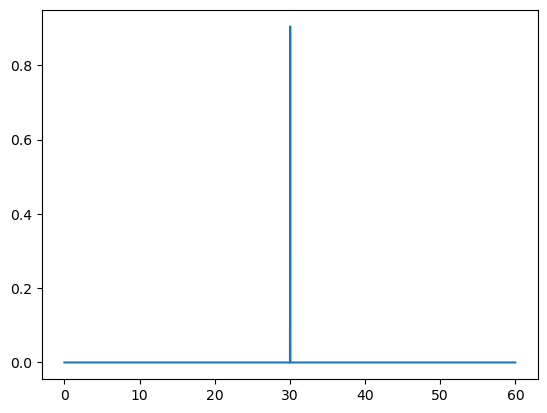

In [5]:
plt.plot(t_plot, transient_signal)
plt.show()

Wavelet transform

In [6]:
# WPT transform
tr_ob = wpt.dwpt(data, levels, wavelet, mode)
tr_ob.calc_frequencies(sampling_rate)

# reconstruct each node separately
wpt_df = pd.DataFrame(
    columns=[
        "node",
        "inverse",
        "fft",
        "energy",
        "kurtosis",
        "crest",
        "entropy",
        "skewness",
    ]
)

total_energy = stats.calc_energy(data)

# calculate energy, kurtosis, and crest factor of reconstructed signals
counter = 0
for node in tr_ob.get_level(level=levels, order="freq"):
    node_data = node.data  # coefficients from transform

    # calculate inverse transform
    path = node.path
    rec_nodes = tr_ob.packet_nodes_for_rec(keep=[path])
    coeffs = tr_ob.nodes2data(rec_nodes)
    inverse = inv.inv_dwpt(coeffs, wavelet)[:signal_length]
    inverse_signal_length = len(inverse)

    # calculate fft of inverse
    fft = np.fft.fft(inverse)[0 : int(inverse_signal_length / 2)] / (
        inverse_signal_length * 0.5
    )

    # calculate statistical measures
    entropy_node = stats.calc_entropy(node.energy, total_energy)
    kurtosis = stats.calc_kurtosis(node_data)
    skewness = stats.calc_skewness(node_data)
    crest = stats.calc_crest_factor(node_data)

    wpt_df.loc[counter, "node"] = node
    wpt_df.loc[counter, "inverse"] = inverse
    wpt_df.loc[counter, "fft"] = fft
    wpt_df.loc[counter, "energy"] = node.energy
    wpt_df.loc[counter, "kurtosis"] = kurtosis
    wpt_df.loc[counter, "crest"] = crest
    wpt_df.loc[counter, "entropy"] = entropy_node
    wpt_df.loc[counter, "skewness"] = skewness
    counter += 1

In [7]:
wpt_df

,node,inverse,fft,energy,kurtosis,crest,entropy,skewness
0,<wavelet_transform.wpt.transform_object.Node o...,"[0.019036719455468983, 0.019185248788602376, 0...","[(0.0019862352807629934+0j), (-0.0014680230320...",0.005628,6.306295,0.800213,0.128893,-0.136786
1,<wavelet_transform.wpt.transform_object.Node o...,"[0.01634784085576505, 0.016732597000477783, 0....","[(8.435607720534841e-06+0j), (8.43482044160944...",0.00489,7.315833,2.914273,0.116208,-0.503084
2,<wavelet_transform.wpt.transform_object.Node o...,"[0.016230005189041476, 0.012438243840423614, 0...","[(-6.03349038964492e-06+0j), (-6.0337780037554...",0.025023,4.088708,-0.64782,0.343979,0.425915
3,<wavelet_transform.wpt.transform_object.Node o...,"[-0.004519933878883329, -0.00425571556422557, ...","[(-2.178215105363851e-05+0j), (-2.178232399095...",0.819447,3.300508,-3.362455,-6.277618,-0.027202
4,<wavelet_transform.wpt.transform_object.Node o...,"[-0.0003014313465409808, 0.0018587487023055606...","[(1.0459691114603364e-05+0j), (1.0459747846400...",0.022701,4.297534,-1.849583,0.325617,0.160427
5,<wavelet_transform.wpt.transform_object.Node o...,"[0.0052971225567323066, 0.0025028394621366213,...","[(9.742170580053112e-06+0j), (9.74219902674120...",0.005305,6.26207,1.954642,0.123421,0.225421
6,<wavelet_transform.wpt.transform_object.Node o...,"[0.005712238898715922, 0.004789240336369394, 0...","[(1.9346883561136972e-06+0j), (1.9346948144408...",0.004167,4.986348,-0.674574,0.103109,-0.178374
7,<wavelet_transform.wpt.transform_object.Node o...,"[0.018051279436319703, 0.01731588545060641, 0....","[(-2.1968881681099596e-06+0j), (-2.19689924508...",1.840576,3.288662,-3.875932,-23.239118,-0.023664
8,<wavelet_transform.wpt.transform_object.Node o...,"[-0.07191096047228836, -0.035387010785299815, ...","[(-3.266366289765917e-06+0j), (-3.266365774578...",3.484367,3.243512,-3.875713,-57.638383,-0.038456
9,<wavelet_transform.wpt.transform_object.Node o...,"[-0.007103623642530331, -0.0006868318597127355...","[(-2.618633534788935e-06+0j), (-2.618633195218...",0.004478,6.829662,2.005055,0.108838,0.695925


### Heisenberg visualisation

Making the heisenberg plot of the dwpt transform

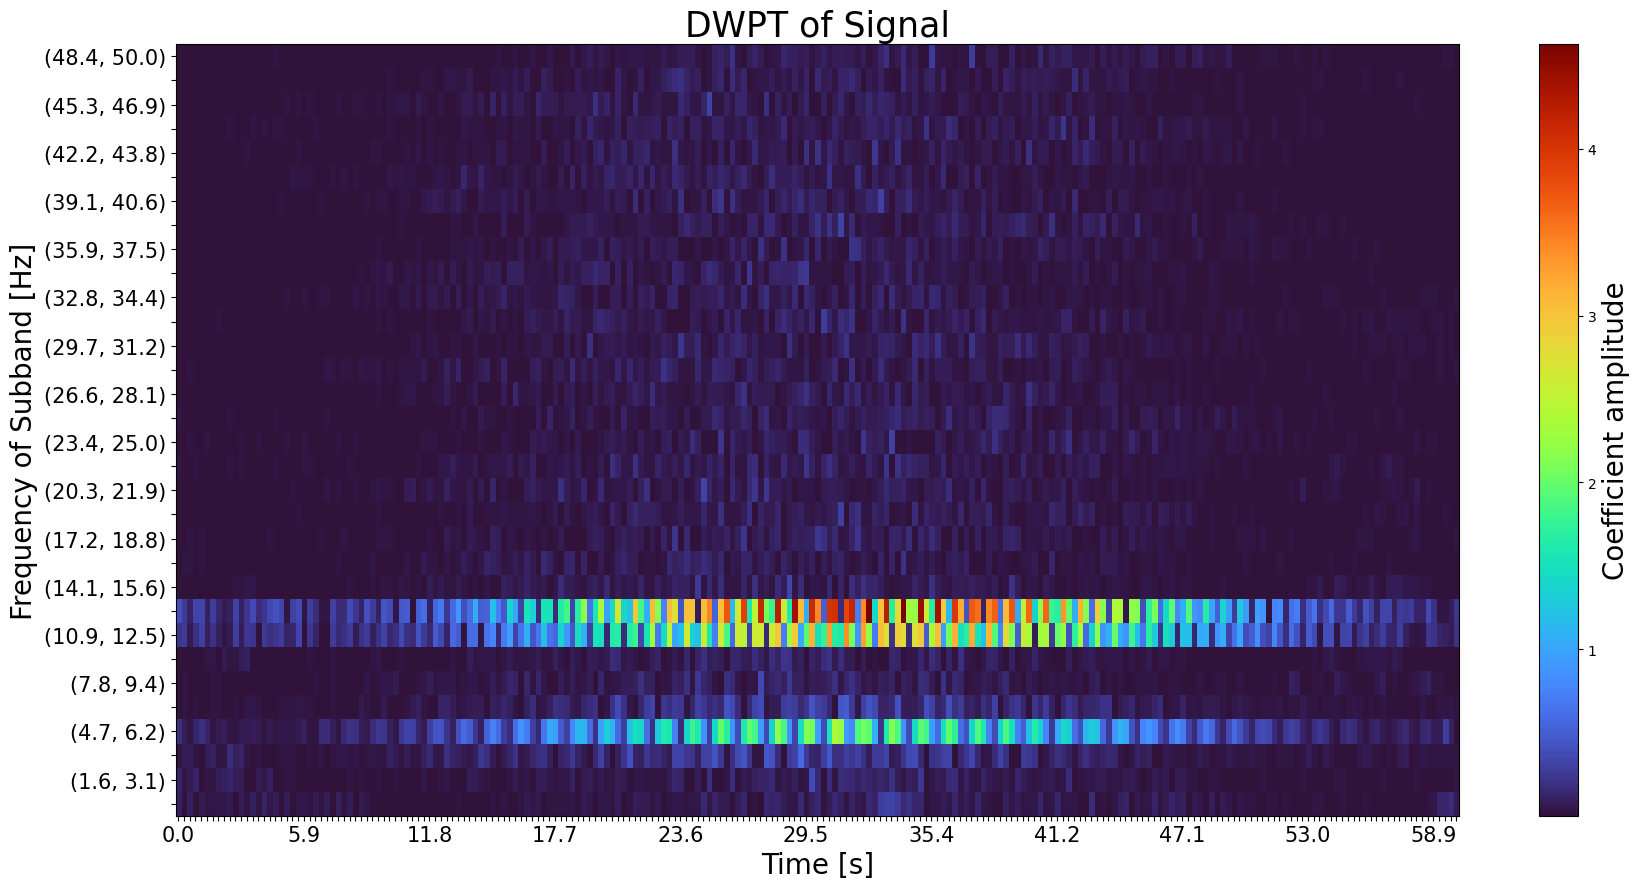

In [8]:
plot.heisenberg(tr_ob, max(t_plot))

<Axes: >

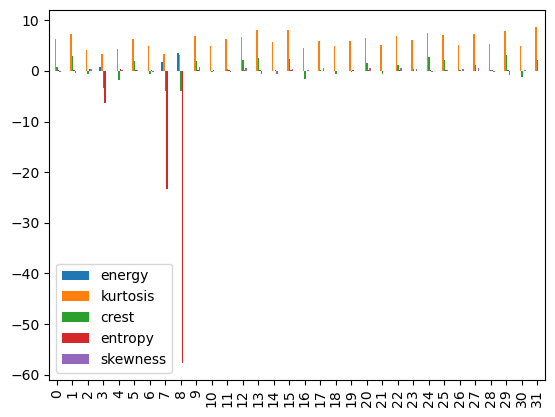

In [9]:
wpt_df.plot.bar()

### K-means

k-means clustering on the calculated statistics from the output of the DWPT

In [10]:
from sklearn import metrics
from collections import defaultdict
from time import time

evaluations = []
evaluations_std = []


def fit_and_evaluate(km, X, name=None, n_runs=5):
    name = km.__class__.__name__ if name is None else name

    train_times = []
    scores = defaultdict(list)
    for seed in range(n_runs):
        km.set_params(random_state=seed)
        t0 = time()
        km.fit(X)
        train_times.append(time() - t0)
        scores["Homogeneity"].append(metrics.homogeneity_score(labels, km.labels_))
        scores["Completeness"].append(metrics.completeness_score(labels, km.labels_))
        scores["V-measure"].append(metrics.v_measure_score(labels, km.labels_))
        scores["Adjusted Rand-Index"].append(
            metrics.adjusted_rand_score(labels, km.labels_)
        )
        scores["Silhouette Coefficient"].append(
            metrics.silhouette_score(X, km.labels_, sample_size=2000)
        )
    train_times = np.asarray(train_times)

    print(f"clustering done in {train_times.mean():.2f} ± {train_times.std():.2f} s ")
    evaluation = {
        "estimator": name,
        "train_time": train_times.mean(),
    }
    evaluation_std = {
        "estimator": name,
        "train_time": train_times.std(),
    }
    for score_name, score_values in scores.items():
        mean_score, std_score = np.mean(score_values), np.std(score_values)
        print(f"{score_name}: {mean_score:.3f} ± {std_score:.3f}")
        evaluation[score_name] = mean_score
        evaluation_std[score_name] = std_score
    evaluations.append(evaluation)
    evaluations_std.append(evaluation_std)

In [44]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import numpy as np

# training data
classifying_metrics = ["energy", "kurtosis", "skewness"]
data_train = wpt_df[classifying_metrics]

scaler = StandardScaler()
data_train_normalised = scaler.fit_transform(data_train)

# training k-means algorithm
no_clusters = 3
kmeans_params = {
    "init": "k-means++",
    "n_init": 10,
    "max_iter": 100,
    "tol": 1e-8,
    "verbose": 0,
    "algorithm": "elkan",
}

kmeans = KMeans(n_clusters=no_clusters, **kmeans_params)
data_train_predict = kmeans.fit_predict(data_train_normalised)

# get labels and clusters
labels = kmeans.labels_
print(kmeans.cluster_centers_)
print(kmeans.n_iter_)
# centers = kmeans.cluster_centers_
centers = scaler.inverse_transform(kmeans.cluster_centers_)

[[-0.27935573 -0.06503427  0.55556529]
 [ 2.70754648 -1.83935313 -0.27955137]
 [-0.28172498  0.75763831 -1.14140575]]
5


In [45]:
data_train_predict

array([2, 2, 0, 1, 0, 0, 0, 1, 1, 0, 0, 2, 0, 2, 2, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 2, 0, 0, 0, 2, 2, 0, 2], dtype=int32)

In [46]:
cluster_ids, cluster_sizes = np.unique(kmeans.labels_, return_counts=True)
print(f"Number of elements assigned to each cluster: {cluster_sizes}")
print(f"cluster IDs: {cluster_ids}")

Number of elements assigned to each cluster: [20  3  9]
cluster IDs: [0 1 2]


In [47]:
fit_and_evaluate(kmeans, data_train_normalised, name="test")

clustering done in 0.07 ± 0.02 s 
Homogeneity: 0.971 ± 0.058
Completeness: 0.985 ± 0.030
V-measure: 0.978 ± 0.044
Adjusted Rand-Index: 0.982 ± 0.035
Silhouette Coefficient: 0.355 ± 0.002


3 clusters:

- high energy, low kurtosis, low skewness -> harmonic
- low energy, high kurtosis, high skewness -> transient
- low energy, medium kurtosis, low skewness -> noise

### Reassigning Groups

Post-hoc reassignment of groups based on the energy and kurtosis of their clusters.

In [48]:
def assign_labels(centers, labels, sort_by=1):
    """
    assign labels to clusters. Assign the highest cluster number to the centre with
    highest energy. Then assign the rest in order of sort_by. The group numbers are reassigned
    to 1-indexed groups.

    Paramaters
    -----------
    centers: array
        array where each row is a centre of a cluster
    labels: list
        list of group assignments to reassign
    sort_by: int
        always sort out the highest energy because the harmonic can be separated
        from the rest by its much greater energy. Otherwise, sort by attribute
        number = sort_by of the centres. e.g. sort_by == 1 will sort the rest
        by kurtosis, sort_by == 2 will sort by crest factor etc.
    """
    # sort labels by energy, highest cluster energy is highest group number
    sort_by_energy = np.argsort(centers[:, 0])

    # sort rest of the labels by kurtosis
    sort_rest = np.argsort(centers[:, sort_by])

    sort_rest = np.delete(
        sort_rest,  # delete highest energy group form kurtosis
        np.where(sort_rest == sort_by_energy[-1])[0][0],
        axis=0,
    )
    sort_rest = np.append(sort_rest, None)

    # create mapping from old cluster labels to new cluster labels
    mapping = {}
    for new_label, index in enumerate(zip(sort_by_energy, sort_rest)):
        if new_label == len(sort_by_energy) - 1:  # highest group no has highest energy
            mapping[index[0]] = new_label + 1
        else:
            mapping[index[1]] = (
                new_label + 1
            )  # other group numbers are arranged by kurtosis

    # update labels
    reassigned_labels = [mapping[label] for label in labels]
    return reassigned_labels

In [49]:
reassigned_labels = assign_labels(centers, labels)

### Plot result

Plot the assigned group against the frequency of the node. 

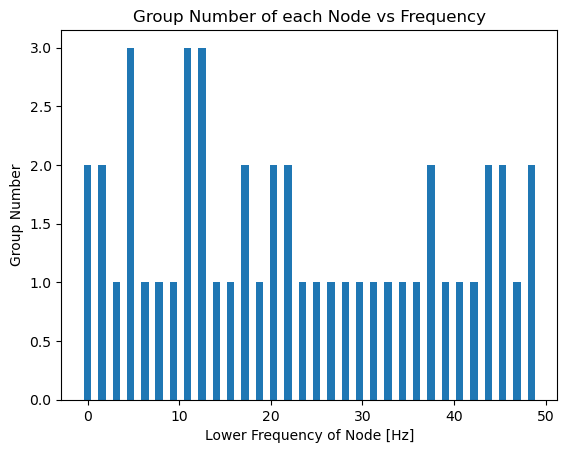

In [50]:
# plot regular k-means
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], reassigned_labels)
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

### PCA

PCA is applied to reduce the dimenisonality of the input features before performing k-means. The centers are converted back to pre-PCA coordinates. The group numbers are sorted based on energy and kurtosis.

In [51]:
# apply PCA to training data
pca = PCA(n_components=data_train.shape[1])
data_pca = pca.fit_transform(data_train_normalised)

# training k-means algorithm on the reduced data
kmeans_pca = KMeans(n_clusters=no_clusters, **kmeans_params)
data_train_predict_pca = kmeans_pca.fit_predict(data_pca)

# convert centres back to regular feature space (energy, kurtosis, crest, etc.)
labels_pca = kmeans_pca.labels_
centers_pca = scaler.inverse_transform(
    pca.inverse_transform(kmeans_pca.cluster_centers_)
)
reassigned_pca_labels = assign_labels(centers_pca, labels_pca)

### Plot PCA result

The group number vs frequency for each node is plotted again after PCA is applied.

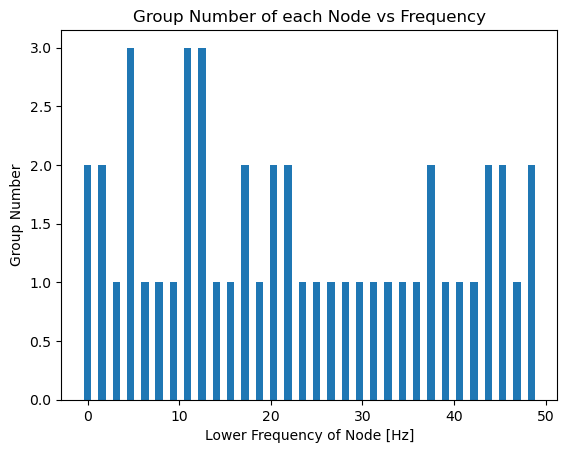

Eigenvectors:
energy, kurtosis, skewness
[[ 0.71 -0.7  -0.07]
 [ 0.05  0.15 -0.99]
 [ 0.7   0.7   0.14]]
Eigenvalues: [1.57 1.04 0.48]


In [52]:
# plot pca k-means
lower_freqs = [node.frequency_range[0] for node in wpt_df["node"]]
plt.bar([node.frequency_range[0] for node in wpt_df["node"]], reassigned_pca_labels)
plt.tick_params
plt.title("Group Number of each Node vs Frequency")
plt.xlabel("Lower Frequency of Node [Hz]")
plt.ylabel("Group Number")
plt.show()

eigenvectors = pca.components_
eigenvalues = pca.explained_variance_

print("Eigenvectors:")
print("energy, kurtosis, skewness")
print(np.round(eigenvectors, 2))

print("Eigenvalues:", np.round(eigenvalues, 2))

### 3d plot

3d plots of the clustering results with axes: energy, kurtosis, crest factor

/tmp/ipykernel_1618846/1246650002.py:7: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  cmap = plt.cm.get_cmap("Set1")


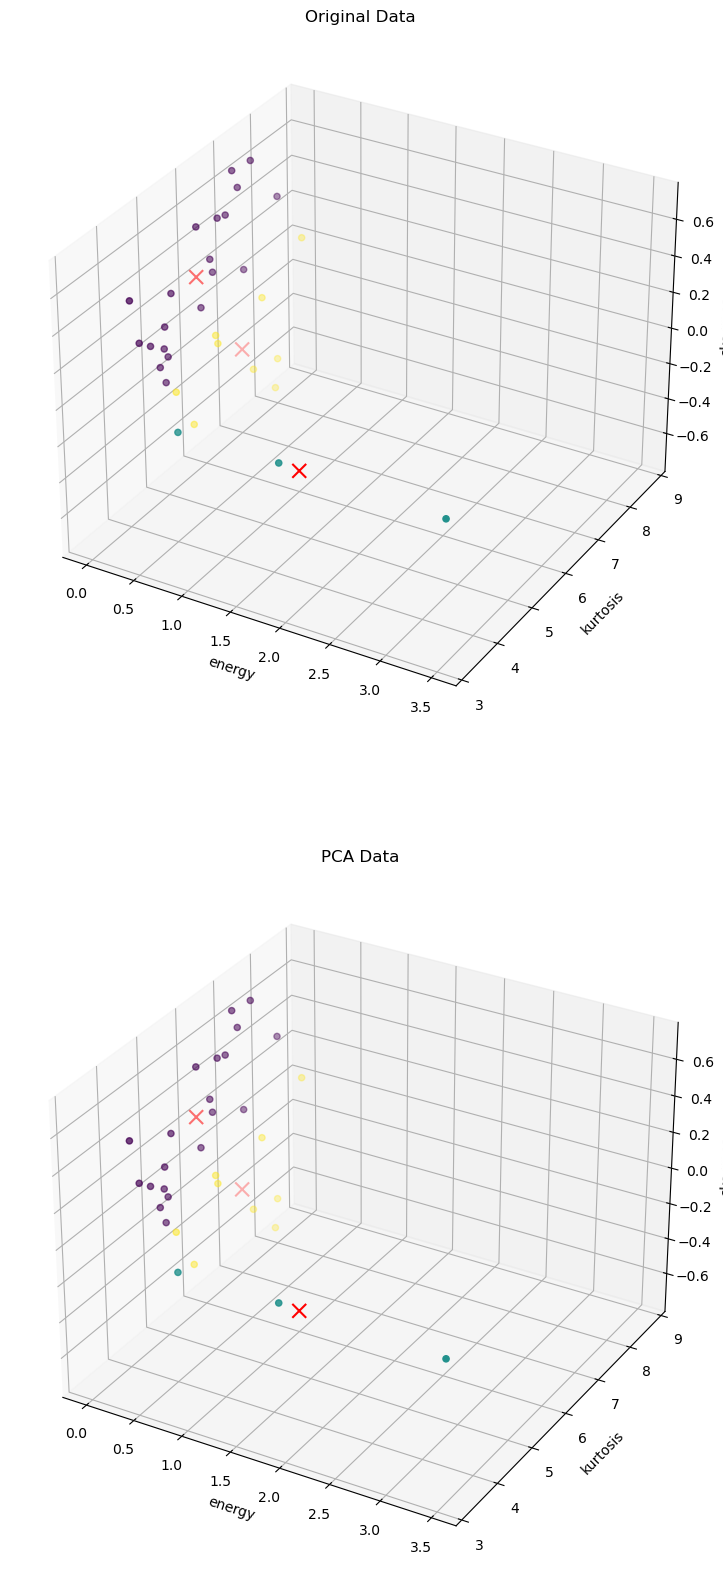

In [53]:
fig, ax = plt.subplots(2, figsize=(20, 20), subplot_kw={"projection": "3d"})

titles = ["Original Data", "PCA Data"]

# plot subplots for PCA data and non-PCA data
for i, ax in enumerate(ax):
    cmap = plt.cm.get_cmap("Set1")
    if i == 0:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers
        labels_scatter = reassigned_labels
        color_map_labels = data_train_predict
    else:
        data_scatter = data_train.values.tolist()
        centers_scatter = centers_pca
        labels_scatter = labels_pca
        color_map_labels = data_train_predict_pca

    ax.scatter(
        [point[0] for point in data_scatter],
        [point[1] for point in data_scatter],
        [point[2] for point in data_scatter],
        # c=[cmap(label) for label in labels_scatter],
        c=color_map_labels,
    )
    ax.scatter(
        centers_scatter[:, 0],
        centers_scatter[:, 1],
        centers_scatter[:, 2],
        c="red",
        marker="x",
        s=100,
    )

    ax.set_xlabel(data_train.columns[0])
    ax.set_ylabel(data_train.columns[1])
    ax.set_zlabel(data_train.columns[2])
    ax.set_title(titles[i])

plt.show()

### Results

Plotting the reconstructed waves at each node alongside their assigned group number.

In [54]:
def plot_reconstructions(wpt_recon_df, group=None):
    for i in range(wpt_recon_df.shape[0]):  # highest energy, kurtosis, etc.
        fig, ax = plt.subplots(
            2, figsize=(11, 8)
        )  # plot reconstructed wave and its fft
        freq_r = wpt_recon_df["node"].values.tolist()[i].frequency_range
        ax[0].plot(
            t_plot,
            wpt_recon_df["inverse"].values.tolist()[i],
        )
        title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz]"
        if group is not None:
            title = f"Reconstructed sub-band [{freq_r[0]}- {freq_r[1]} Hz] group: {group[i]}"
        ax[0].set_title(title)
        ax[0].set_xlabel("time")
        ax[0].set_ylabel("amplitude")
        ax[1].stem(
            freq,
            np.abs(wpt_recon_df["fft"].values.tolist()[i]),
            linefmt="b",
            markerfmt=" ",
            basefmt="-b",
            use_line_collection=True,
        )
        ax[1].set_title("FFT of reconstructed sub-band")
        ax[1].set_xlabel("Frequency")
        ax[1].set_ylabel("Power")
        ax[1].set_xlim(
            max(0, freq_r[0] - fft_lim), min(sampling_rate / 2, freq_r[1] + fft_lim)
        )
        ax[1].grid()
        fig.tight_layout()
        plt.show()
        print(wpt_recon_df.iloc[i, 3:])

Change to group=reassign_pca_labels to display the groups assigned using PCA

In [55]:
# plot_reconstructions(wpt_df, group=reassigned_labels)
# plot_reconstructions(wpt_recon_df, group=reassigned_pca_labels)

In [56]:
THR_Factor = 0.1
harmonics_data = wpt_df[
    data_train["energy"] > THR_Factor * np.max(data_train["energy"])
]
harmonics_data = harmonics_data.sort_values(by="energy", ascending=False)

In [57]:
transient_data = wpt_df[
    (data_train["kurtosis"] > THR_Factor * np.max(data_train["kurtosis"]))
    & (data_train["skewness"] > THR_Factor * np.max(data_train["skewness"]))
]
harmonics_data = harmonics_data.sort_values(by="kurtosis", ascending=False)

/tmp/ipykernel_1618846/4000348810.py:17: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


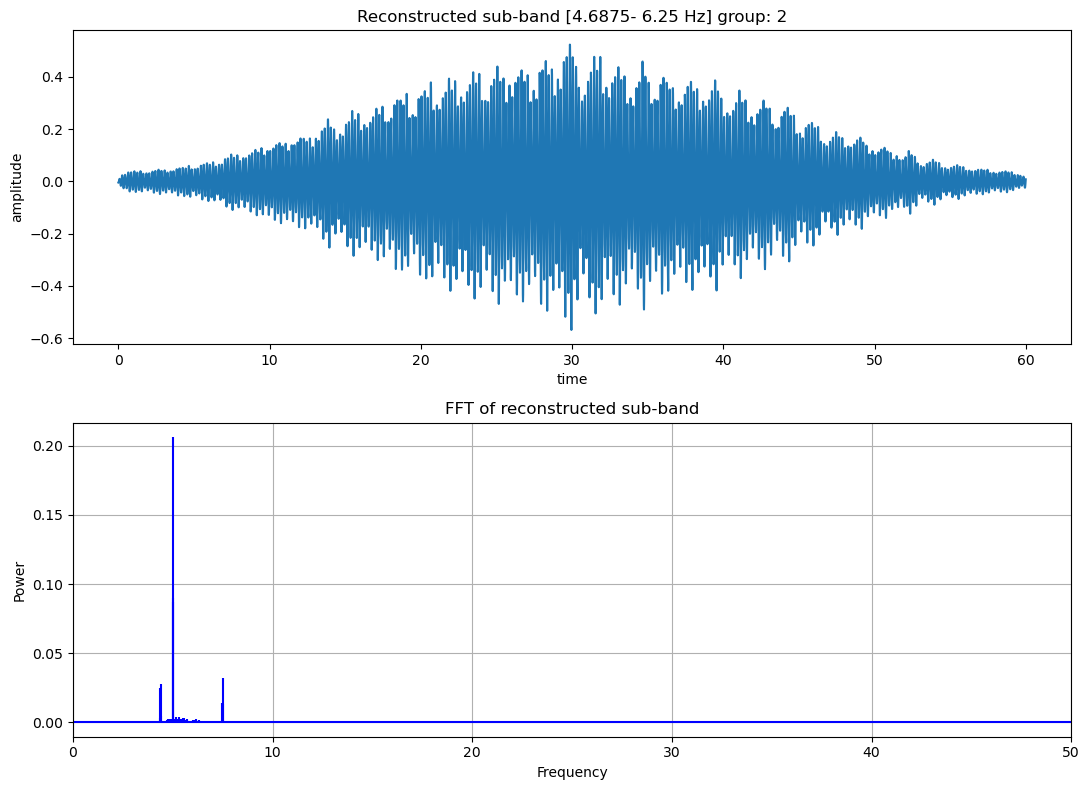

energy      0.819447
kurtosis    3.300508
crest      -3.362455
entropy    -6.277618
skewness   -0.027202
Name: 3, dtype: object


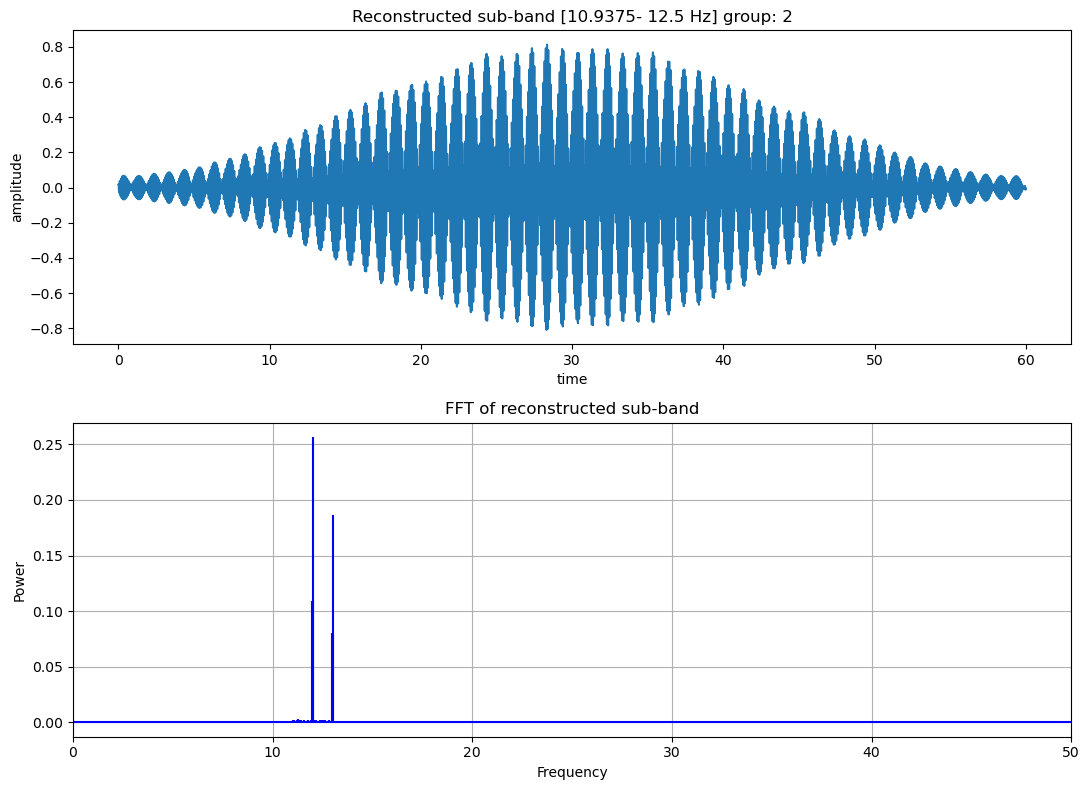

energy       1.840576
kurtosis     3.288662
crest       -3.875932
entropy    -23.239118
skewness    -0.023664
Name: 7, dtype: object


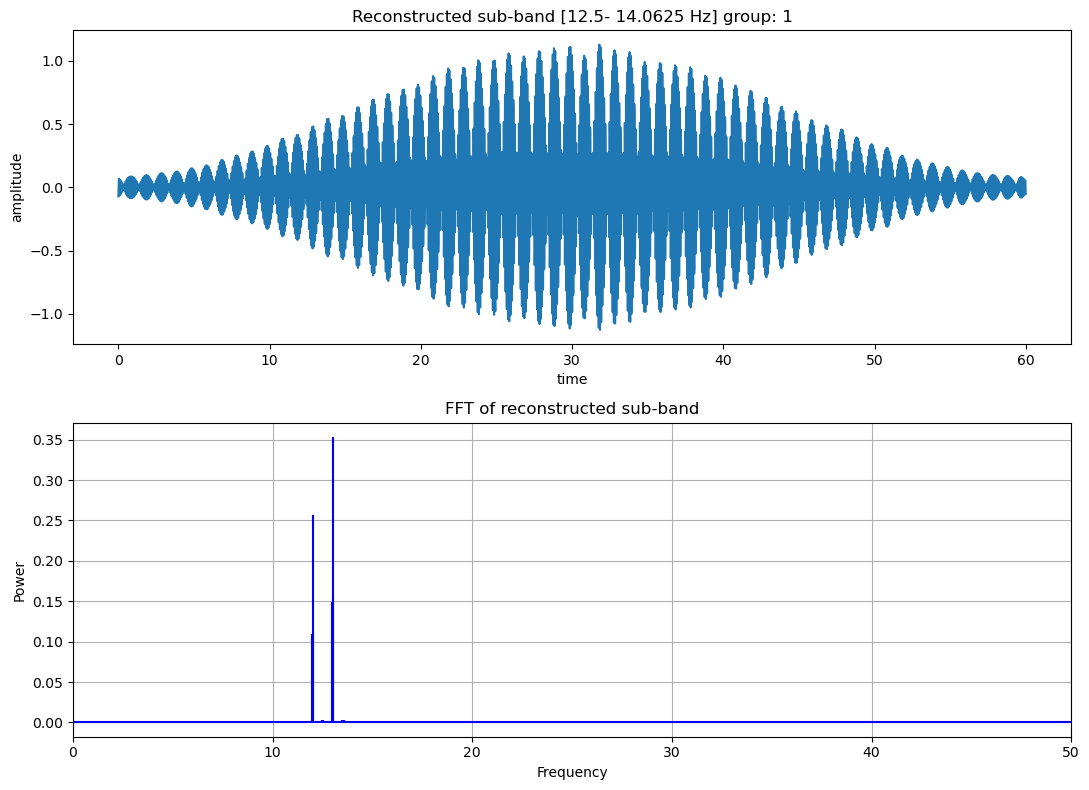

energy       3.484367
kurtosis     3.243512
crest       -3.875713
entropy    -57.638383
skewness    -0.038456
Name: 8, dtype: object


In [58]:
plot_reconstructions(harmonics_data, group=reassigned_labels)

/tmp/ipykernel_1618846/4000348810.py:17: MatplotlibDeprecationWarning: The 'use_line_collection' parameter of stem() was deprecated in Matplotlib 3.6 and will be removed two minor releases later. If any parameter follows 'use_line_collection', they should be passed as keyword, not positionally.
  ax[1].stem(


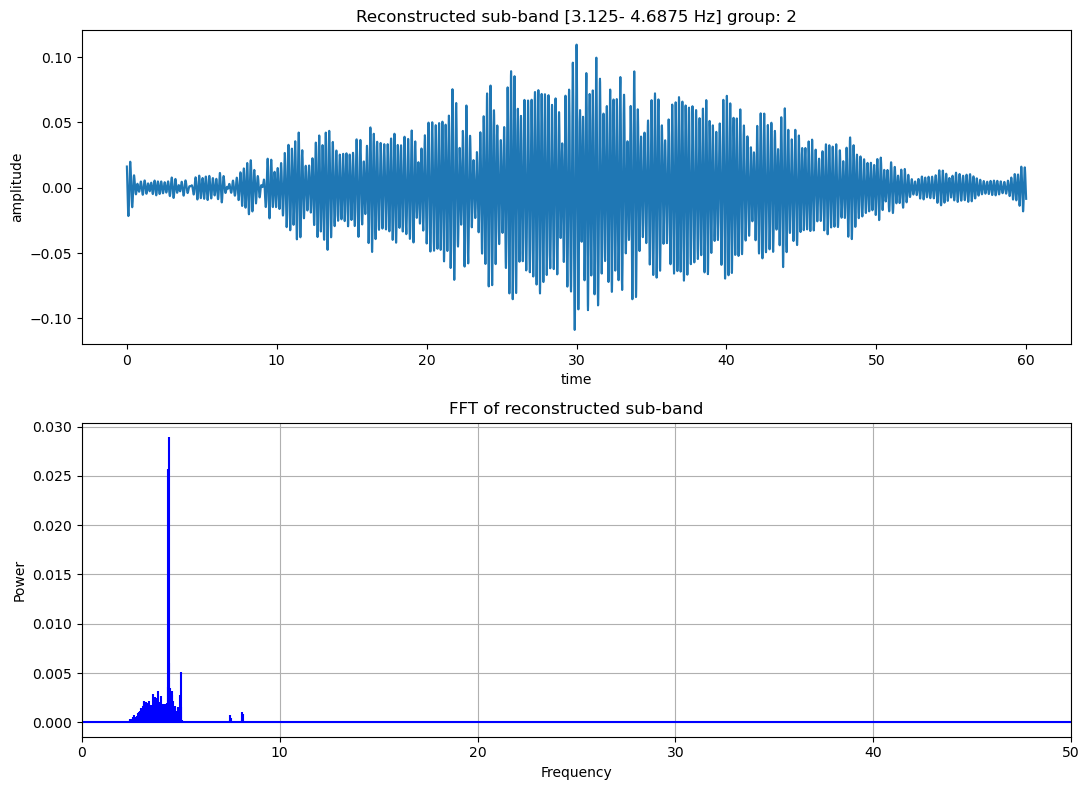

energy      0.025023
kurtosis    4.088708
crest       -0.64782
entropy     0.343979
skewness    0.425915
Name: 2, dtype: object


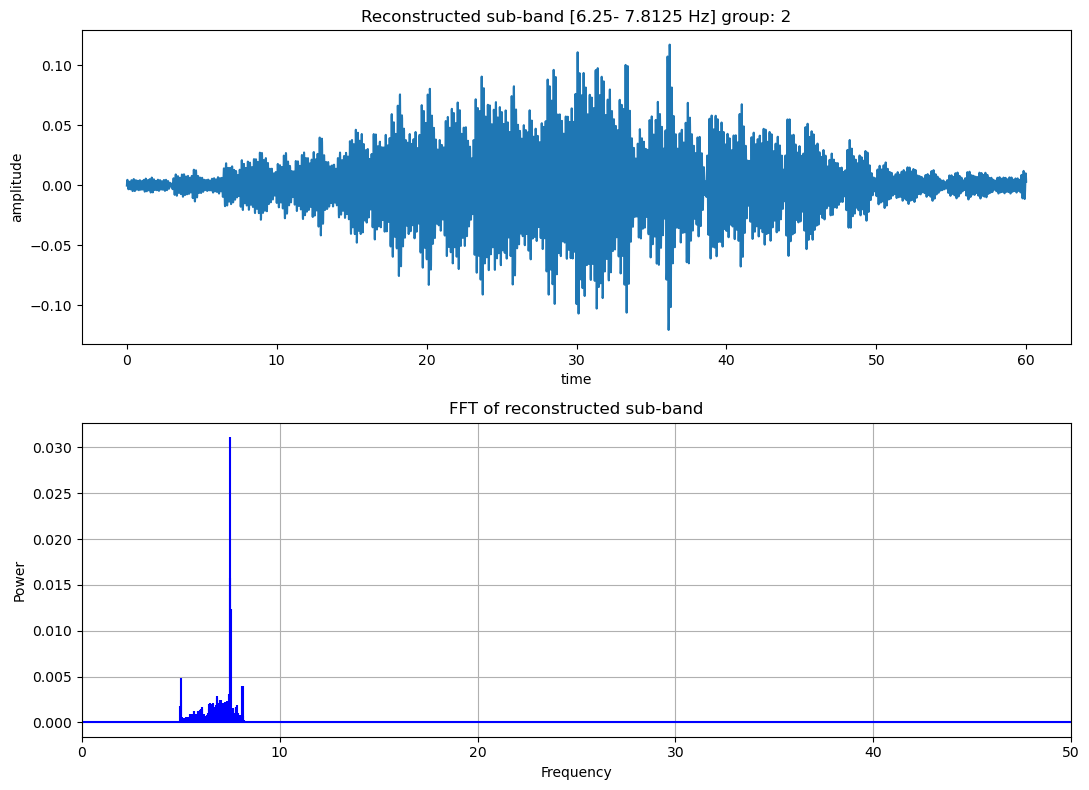

energy      0.022701
kurtosis    4.297534
crest      -1.849583
entropy     0.325617
skewness    0.160427
Name: 4, dtype: object


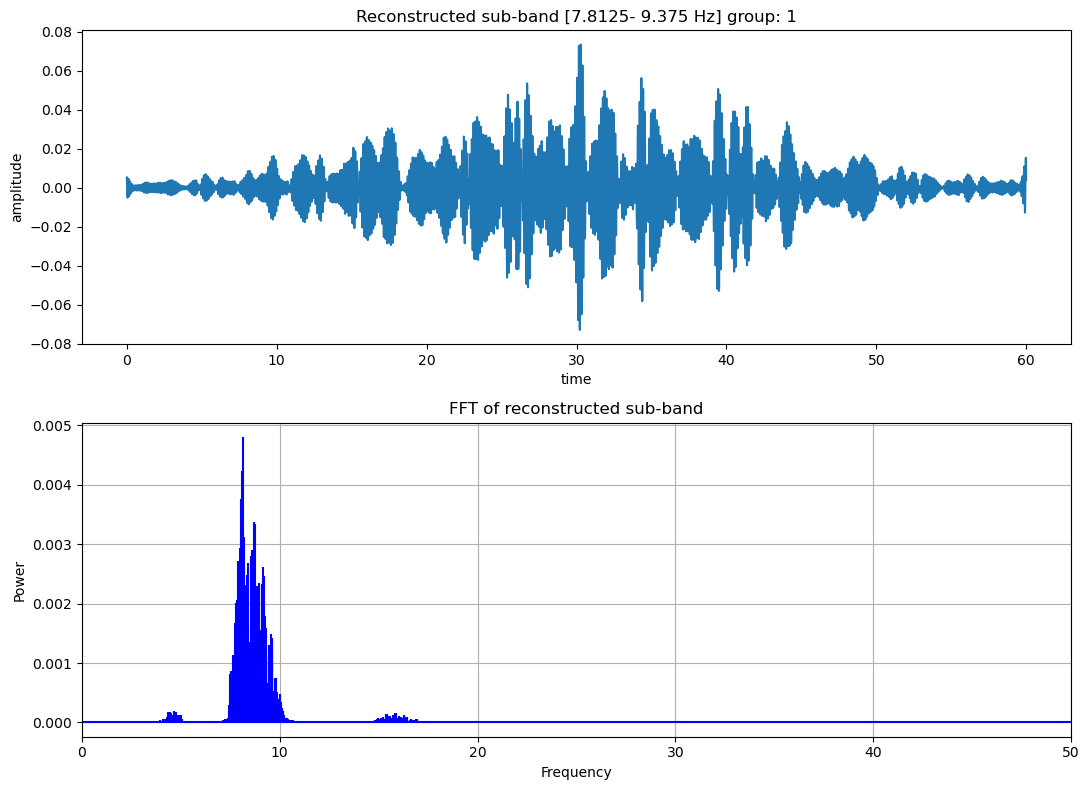

energy      0.005305
kurtosis     6.26207
crest       1.954642
entropy     0.123421
skewness    0.225421
Name: 5, dtype: object


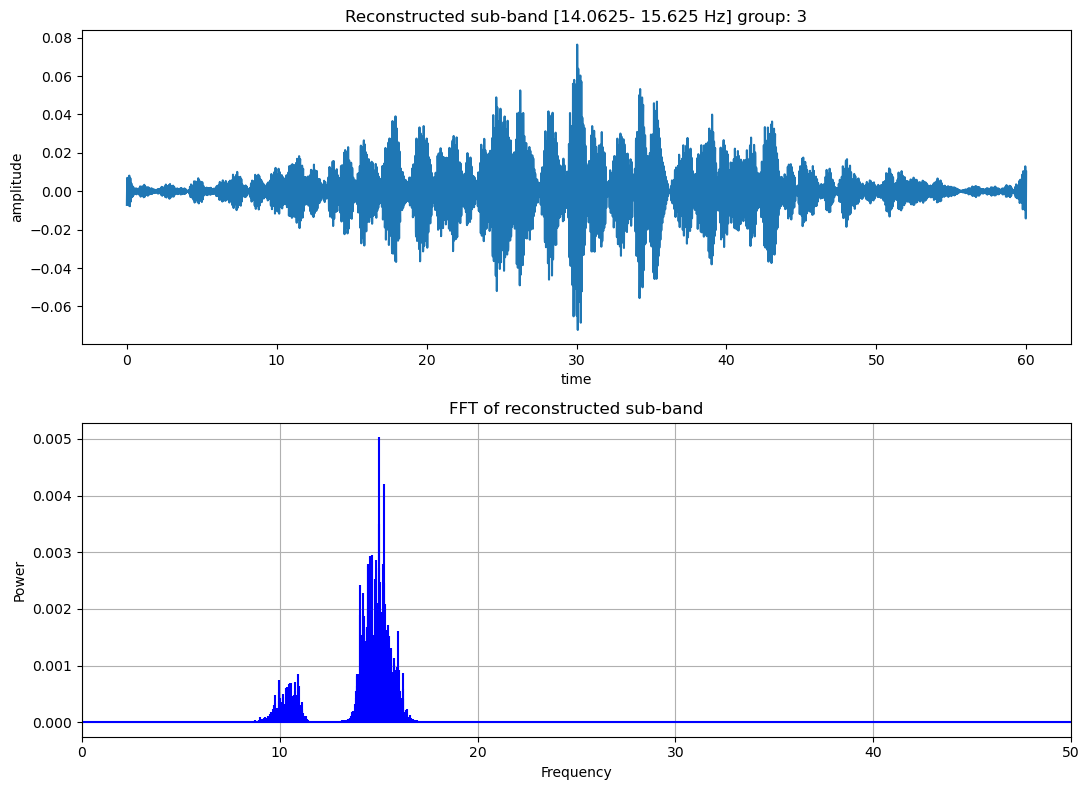

energy      0.004478
kurtosis    6.829662
crest       2.005055
entropy     0.108838
skewness    0.695925
Name: 9, dtype: object


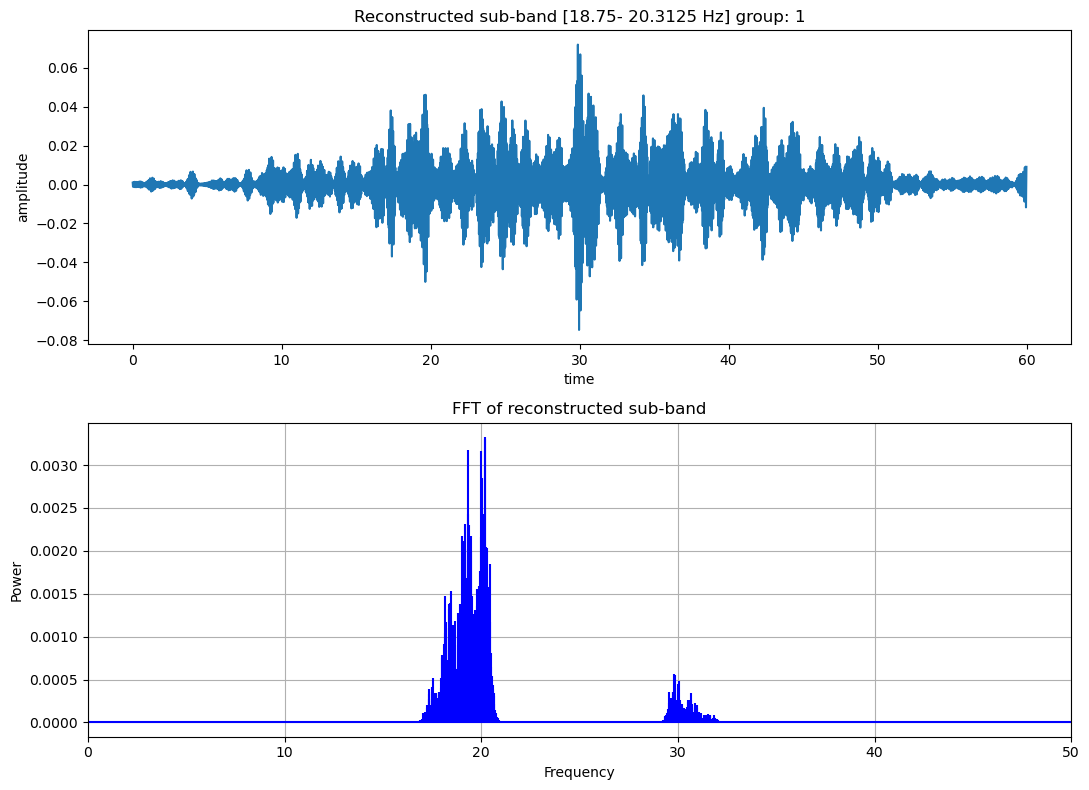

energy      0.003518
kurtosis    6.635594
crest       2.234976
entropy     0.090701
skewness    0.482271
Name: 12, dtype: object


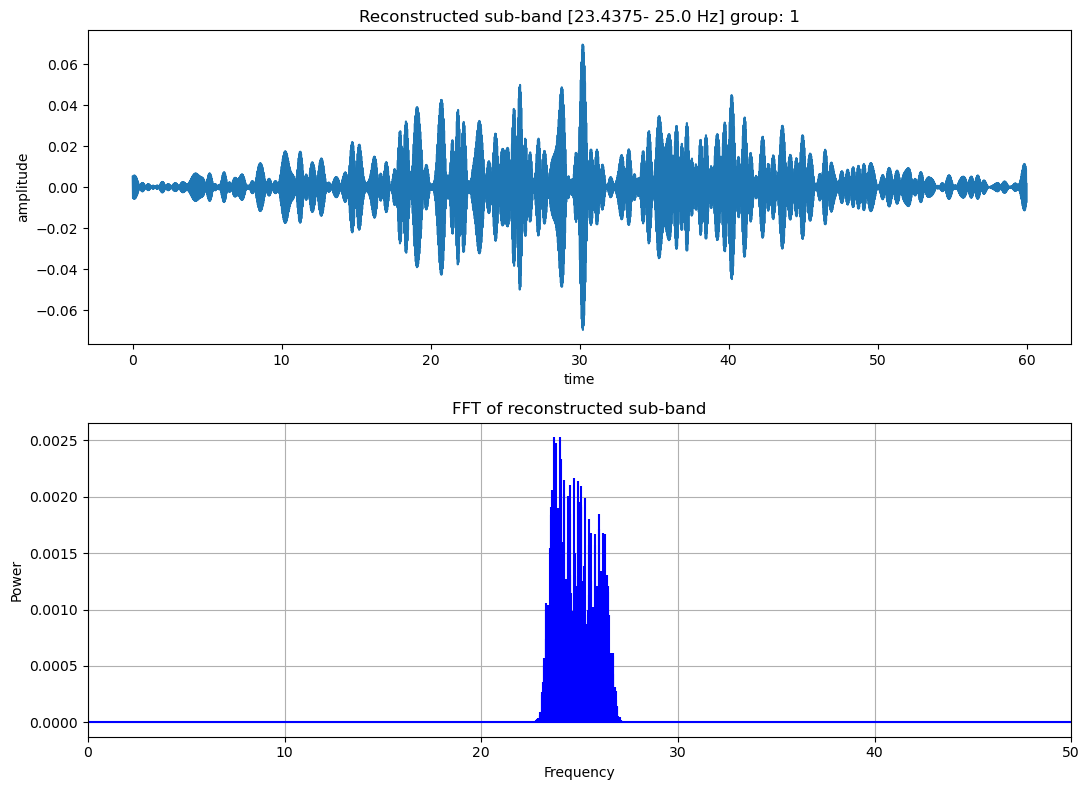

energy      0.003509
kurtosis    8.048406
crest       2.349885
entropy     0.090528
skewness    0.367121
Name: 15, dtype: object


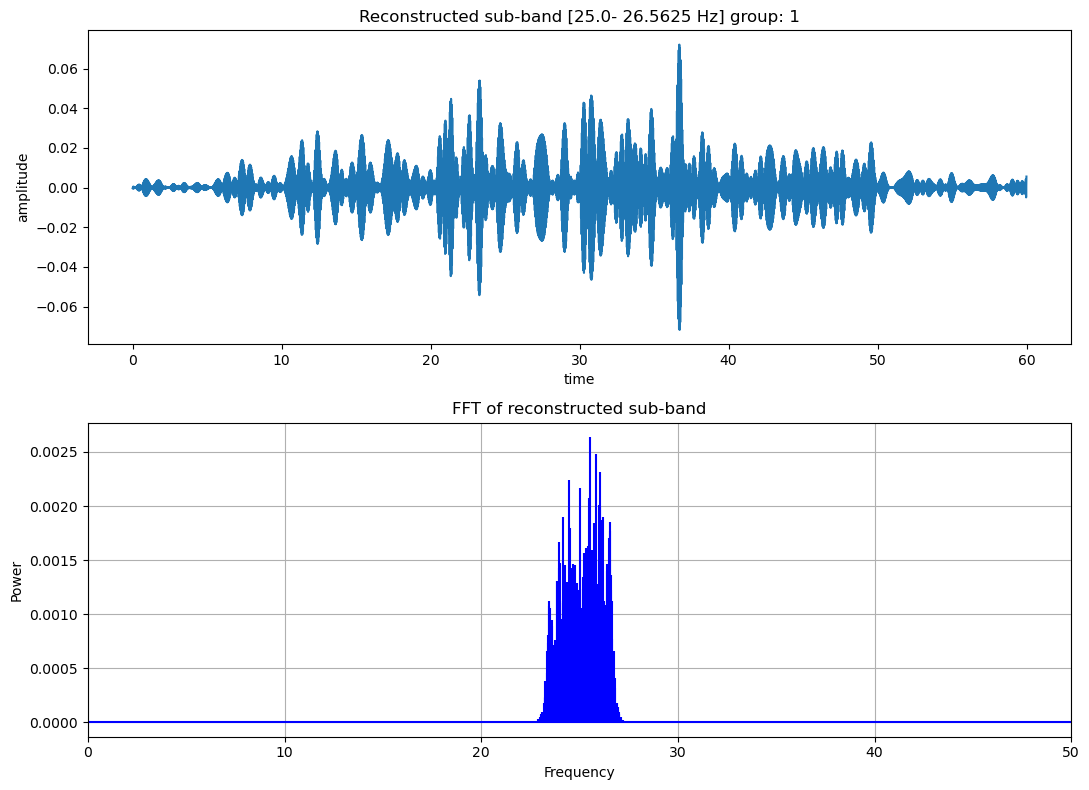

energy      0.003104
kurtosis    4.622405
crest      -1.602565
entropy     0.082421
skewness    0.085511
Name: 16, dtype: object


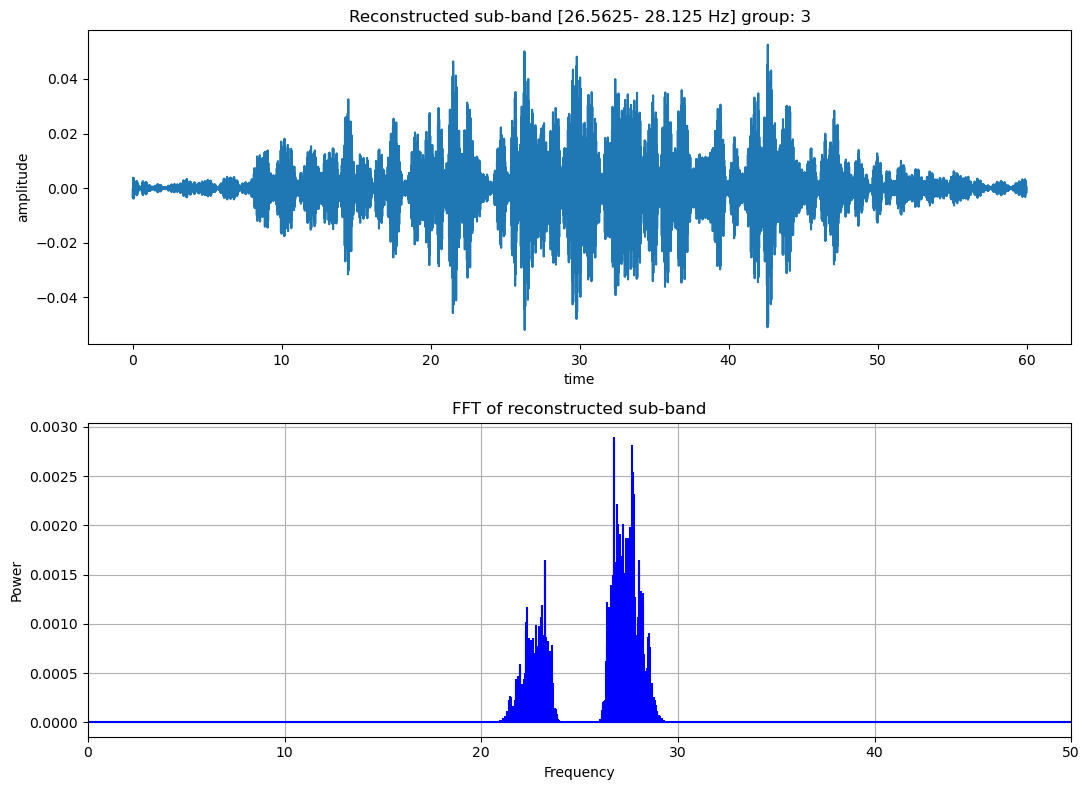

energy      0.002852
kurtosis    5.863328
crest       0.116172
entropy     0.077205
skewness    0.537949
Name: 17, dtype: object


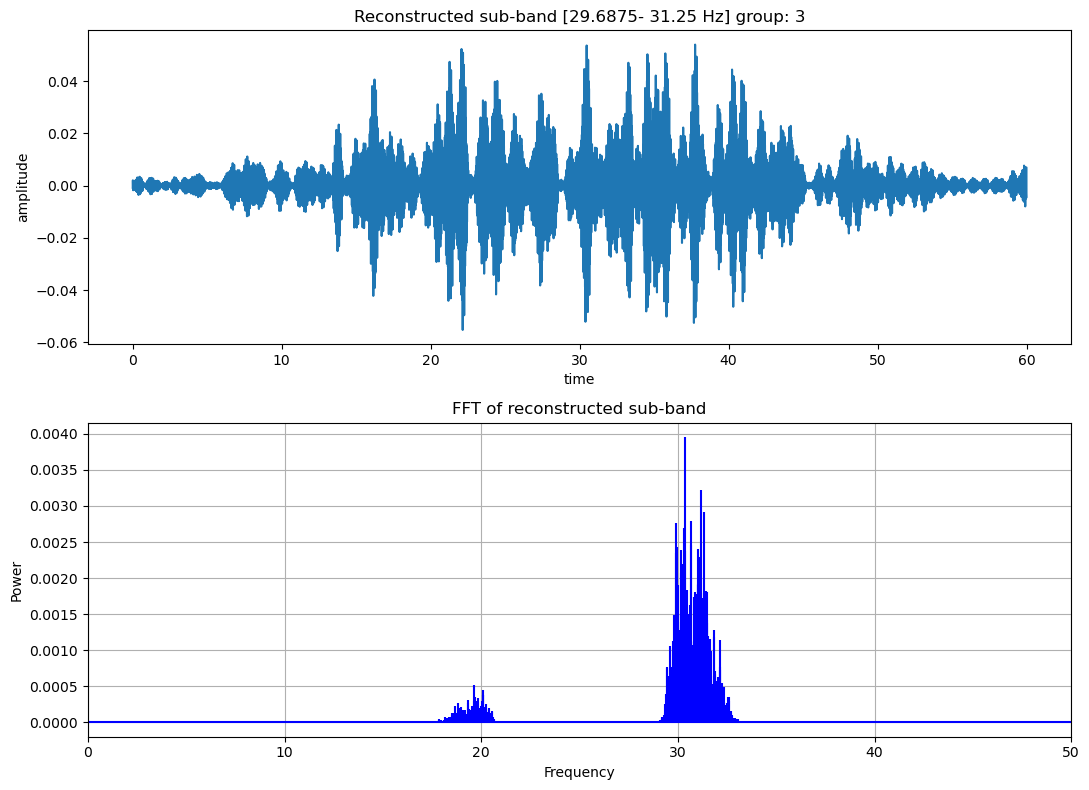

energy      0.003628
kurtosis    5.941576
crest      -0.176224
entropy     0.092852
skewness    0.079748
Name: 19, dtype: object


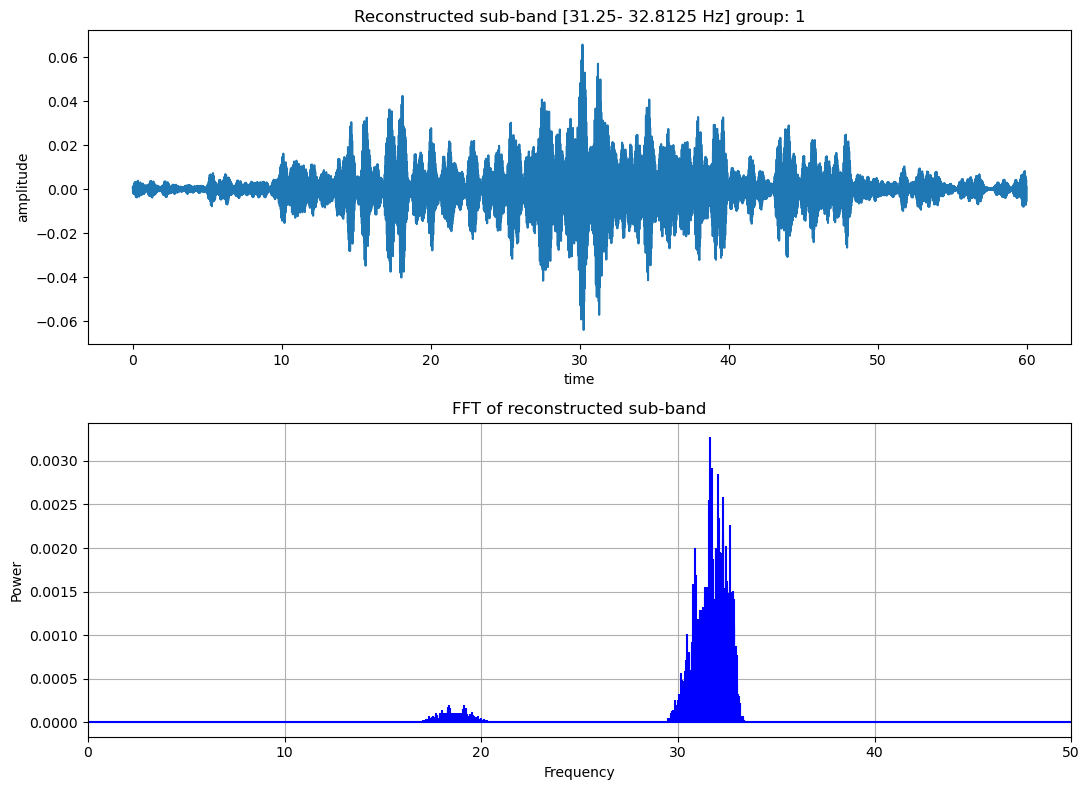

energy      0.003446
kurtosis    6.421381
crest       1.594849
entropy       0.0893
skewness    0.498553
Name: 20, dtype: object


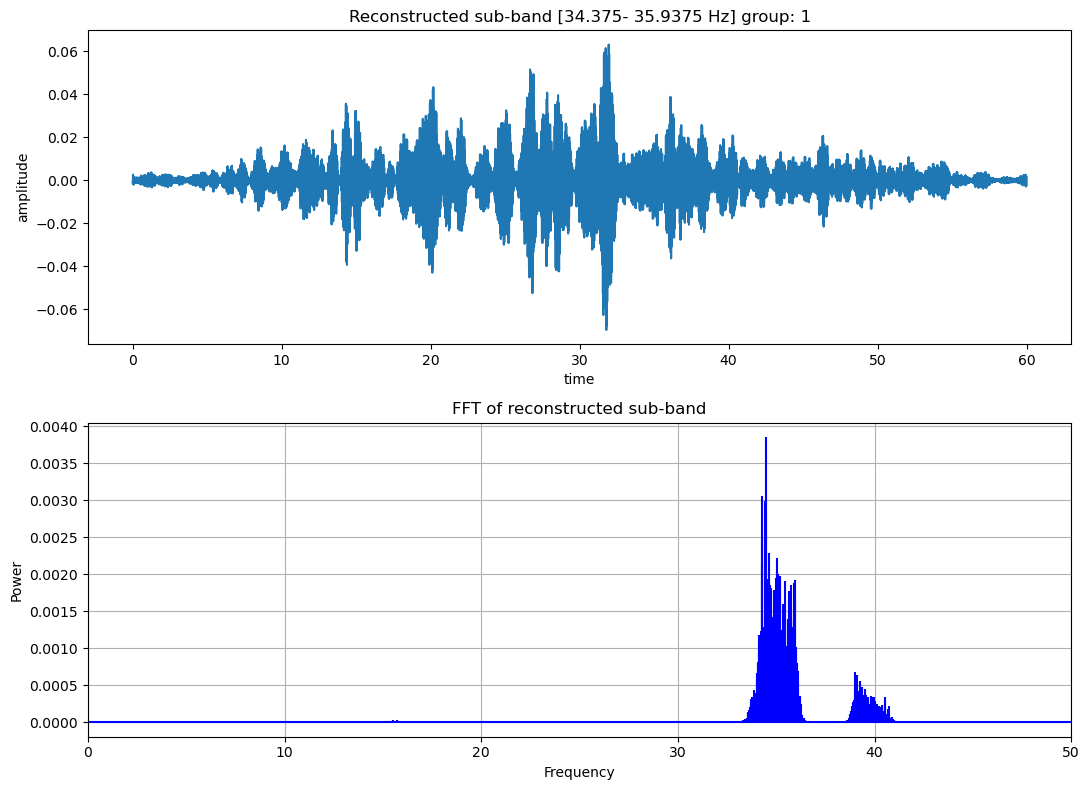

energy      0.003238
kurtosis    6.971951
crest       1.147321
entropy     0.085145
skewness    0.581996
Name: 22, dtype: object


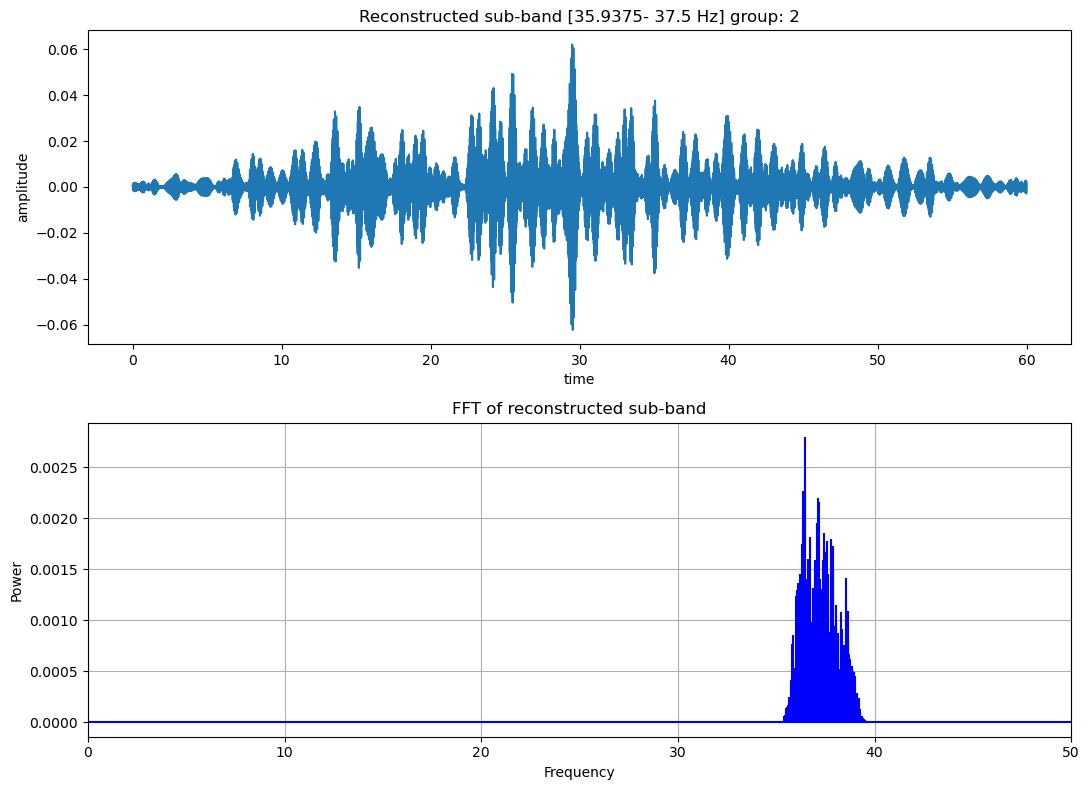

energy      0.002568
kurtosis      6.2061
crest       0.339359
entropy     0.071179
skewness    0.305778
Name: 23, dtype: object


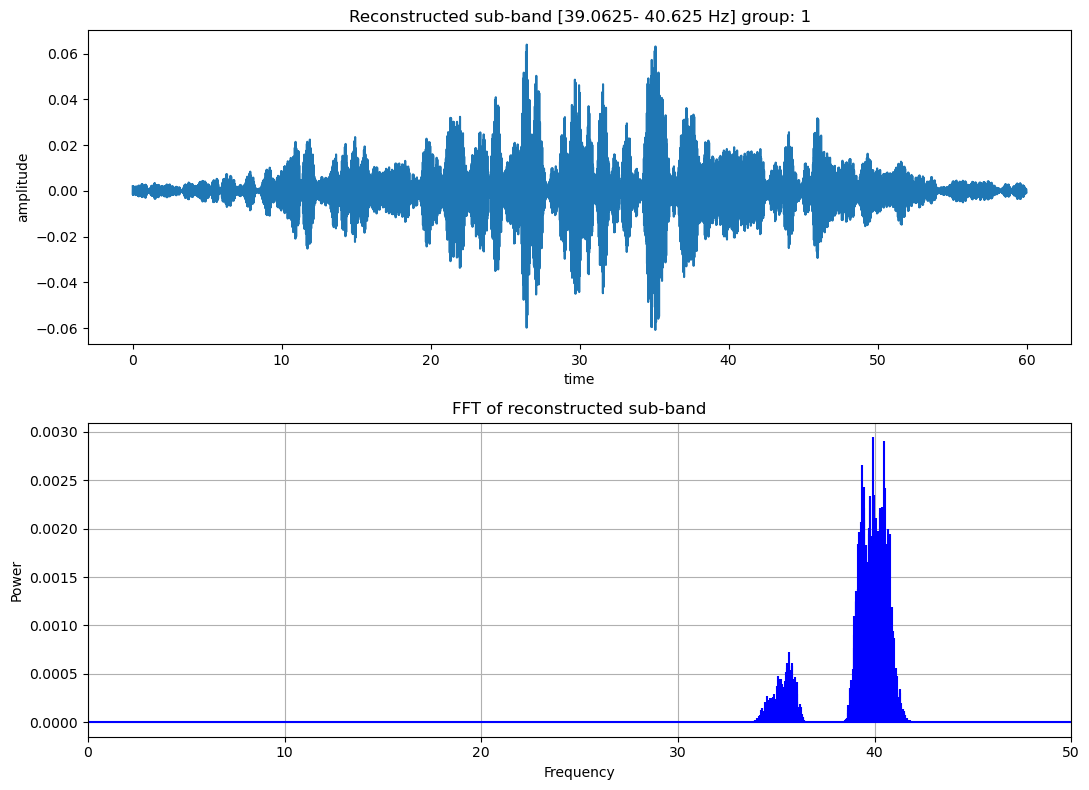

energy      0.003661
kurtosis    7.100454
crest        2.15545
entropy     0.093507
skewness    0.104955
Name: 25, dtype: object


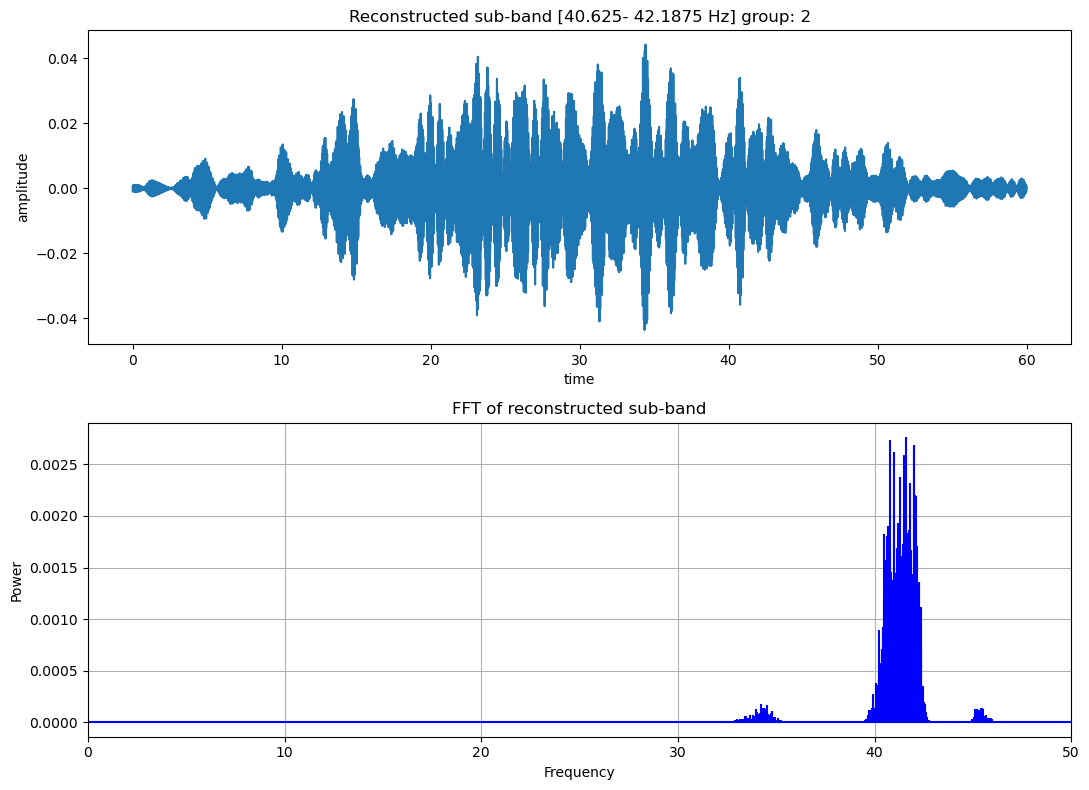

energy      0.002924
kurtosis    5.180018
crest       0.183532
entropy     0.078714
skewness    0.283544
Name: 26, dtype: object


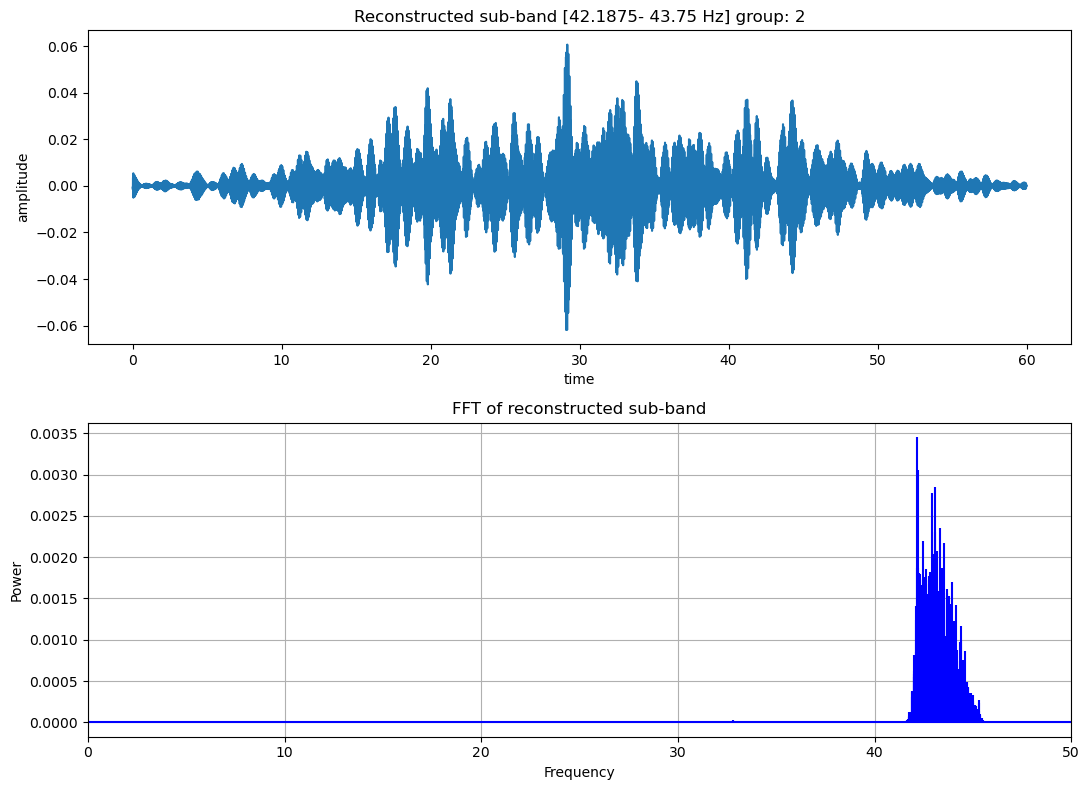

energy      0.003176
kurtosis    7.334592
crest        1.12758
entropy     0.083887
skewness    0.675095
Name: 27, dtype: object


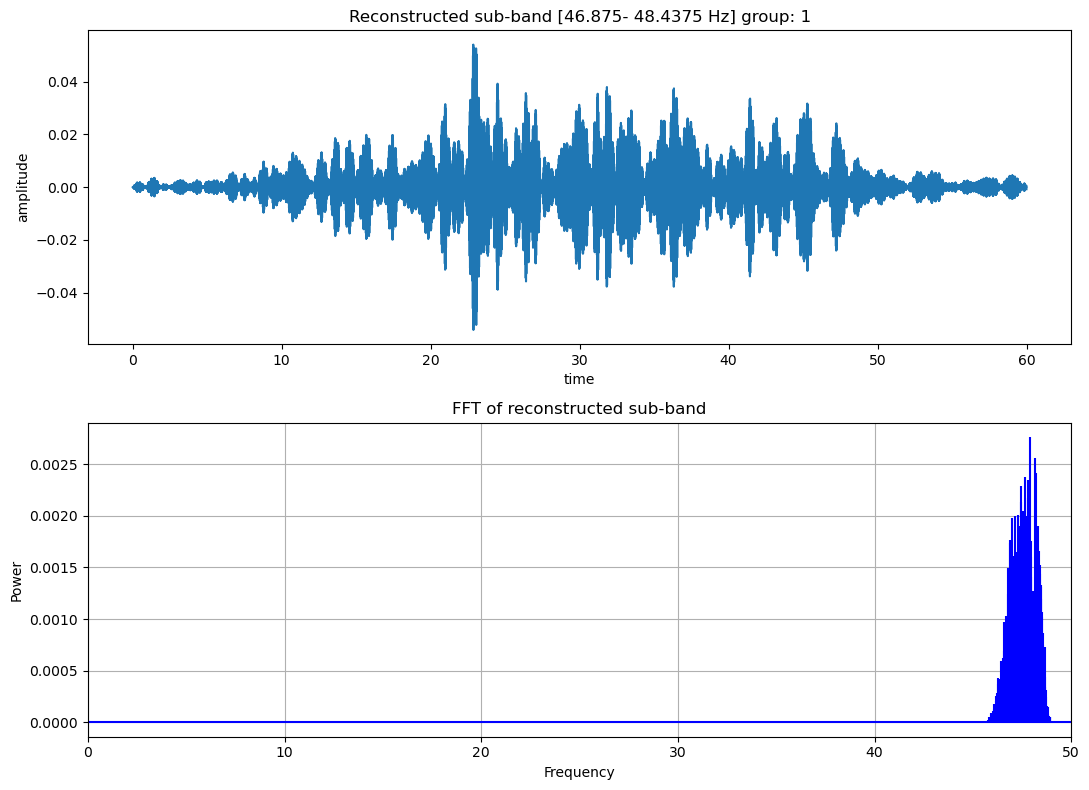

energy      0.002955
kurtosis    4.994865
crest      -1.288292
entropy     0.079349
skewness    0.129614
Name: 30, dtype: object


In [59]:
plot_reconstructions(transient_data, group=reassigned_labels)

In [60]:
harmonics_data["node"].values.tolist()[0].frequency_range

(4.6875, 6.25)

<Axes: >

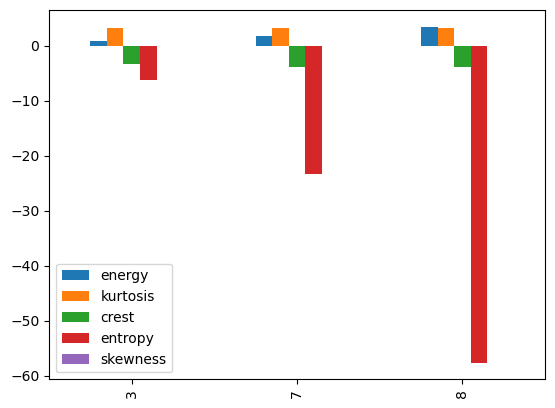

In [61]:
harmonics_data.plot.bar()

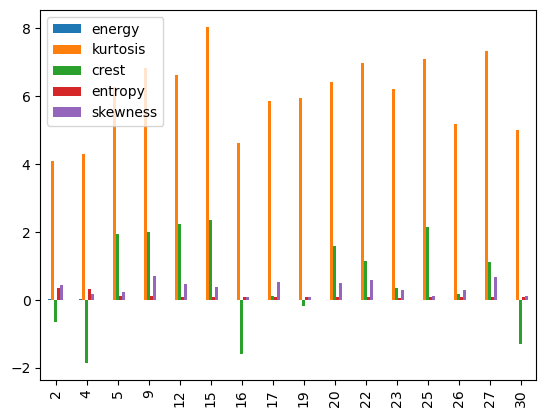

In [62]:
transient_data.plot.bar()
plt.show()